In [39]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.gridspec as gridspec
import matplotlib.patches as patches
import seaborn as sns
import textwrap
from scipy.stats import linregress

In [40]:
plt.style.use('fivethirtyeight')

In [41]:
conn = sqlite3.connect('../data/nba_stats.db')

query = 'SELECT * FROM team_profile'
team_profile_df = pd.read_sql_query(query, conn)
conn.close()

pd.set_option('display.max_columns', None)
team_profile_df.head()

,season_end_year,team_id,team_name,gp,w,l,w_pct,off_rating,ast_pct,pct_uast_fgm,ts_pct,league_off_rating,league_ast_pct,league_pct_uast_fgm,league_ts_pct,team_orating_plus,team_ts_plus,team_possession_residual,team_possession_plus,oreb_pct,tm_tov_pct,team_orating_plus_rank,team_ts_plus_rank,team_possession_plus_rank,pct_uast_fgm_rank,oreb_pct_rank,tm_tov_pct_rank,team_fg_pct,team_3pt_pct,team_ft_pct,team_ppg,finishers,balanced,creators,finishers_q,balanced_q,creators_q
0,2001,1610612737,Atlanta Hawks,82,25,57,0.305,96.9,0.542,0.458,0.500,101.555172,0.610069,0.389931,0.518034,95.416115,96.518671,-1.713859,98.286141,0.313,0.178,27,26,25,29,15,28,0.431,0.357,0.759,91.0,7,4,5,0,2,2
1,2001,1610612738,Boston Celtics,82,36,46,0.439,100.1,0.616,0.384,0.521,101.555172,0.610069,0.389931,0.518034,98.567111,100.572456,-1.904824,98.095176,0.280,0.166,17,12,27,12,26,20,0.428,0.363,0.740,94.6,8,3,4,2,2,1
2,2001,1610612766,Charlotte Hornets,82,46,36,0.561,99.7,0.679,0.321,0.506,101.555172,0.610069,0.389931,0.518034,98.173237,97.676895,0.088417,100.088417,0.315,0.156,19,23,13,2,13,10,0.431,0.346,0.745,91.9,12,2,1,3,1,1
3,2001,1610612741,Chicago Bulls,82,15,67,0.183,95.9,0.665,0.335,0.495,101.555172,0.610069,0.389931,0.518034,94.431428,95.553485,-1.902840,98.097160,0.302,0.173,29,28,26,3,20,25,0.424,0.346,0.739,87.6,7,6,3,3,2,0
4,2001,1610612739,Cleveland Cavaliers,82,30,52,0.366,99.3,0.591,0.409,0.509,101.555172,0.610069,0.389931,0.518034,97.779362,98.256007,-0.782881,99.217119,0.331,0.177,22,22,20,19,7,27,0.442,0.334,0.765,92.2,6,5,7,1,3,2


In [42]:
conn = sqlite3.connect('../data/nba_stats.db')

query = 'SELECT * FROM player_profile'
player_profile_df = pd.read_sql_query(query, conn)
conn.close()

player_profile_df.head()

,player_name,team_name,team_abbreviation,team_id,season_end_year,season,slug,player_id,games_played,minutes_per_game,minutes_played,scoring_plus,pts_plus,ts_plus,per_100_pts,true_shooting_percentage,offensive_win_shares,offensive_box_plus_minus,age,positions,points_per_game,fg_percentage,three_point_percentage,ft_percentage,assists_per_game,offensive_rebounds_per_game,defensive_rebounds_per_game,total_rebounds_per_game,turnovers_per_game,steals_per_game,blocks_per_game,stocks_per_game,per_100_reb,per_100_ast,per_100_stl,per_100_blk,per_100_tov,qualified,qualified_ast,pct_uast_fgm,uast_bin,uast_rating,profile
0,A.C. Green,MIAMI HEAT,MIA,1610612748,2001,2000-2001,greenac01,920,82,17.207317,1411,89.438042,67.943364,94.980695,13.8,0.492,1.1,-2.2,37,POWER FORWARD,4.475610,0.444444,0.000000,0.711712,0.475610,1.304878,2.512195,3.817073,0.548780,0.365854,0.097561,0.463415,11.8,1.5,1.1,0.3,1.7,0,0,0.236,1,-4,Finisher
1,A.J. Guyton,CHICAGO BULLS,CHI,1610612741,2001,2000-2001,guytoaj01,2062,33,19.090909,630,93.027308,83.206003,95.559846,16.9,0.495,0.4,-0.8,22,POINT GUARD,6.000000,0.406250,0.391304,0.833333,1.939394,0.303030,0.787879,1.090909,0.727273,0.272727,0.151515,0.424242,3.1,5.5,0.8,0.4,2.0,0,0,0.308,2,-3,Finisher
2,Aaron McKie,PHILADELPHIA 76ERS,PHI,1610612755,2001,2000-2001,mckieaa01,243,76,31.500000,2394,103.333560,93.052867,105.984556,18.9,0.549,2.3,0.1,28,SHOOTING GUARD,11.552632,0.473389,0.311765,0.768041,4.960526,0.434211,3.657895,4.092105,2.671053,1.394737,0.105263,1.500000,6.7,8.1,2.3,0.2,4.4,1,1,0.447,6,1,Balanced
3,Aaron Williams,NEW JERSEY NETS,NJN,1610612751,2001,2000-2001,williaa01,1425,82,28.487805,2336,100.474240,91.083495,102.895753,18.5,0.533,2.9,-1.3,29,POWER FORWARD,10.219512,0.456923,0.000000,0.787097,1.073171,2.573171,4.621951,7.195122,1.609756,0.719512,1.378049,2.097561,13.0,1.9,1.3,2.5,2.9,1,0,0.377,5,0,Balanced
4,Adam Keefe,GOLDEN STATE WARRIORS,GSW,1610612744,2001,2000-2001,keefead01,228,67,12.477612,836,79.257673,49.726665,86.872587,10.1,0.450,0.1,-3.5,30,POWER FORWARD,2.507463,0.402516,0.333333,0.619048,0.537313,1.343284,1.776119,3.119403,0.597015,0.417910,0.298507,0.716418,12.5,2.2,1.7,1.2,2.4,0,0,0.313,3,-2,Finisher


# Player Charts

In [43]:
conn = sqlite3.connect('../data/nba_stats.db')

query = '''
SELECT * 
FROM player_profile
WHERE points_per_game >= 20.0 AND qualified = 1
'''
twenty_ppg_df = pd.read_sql_query(query, conn)
conn.close()

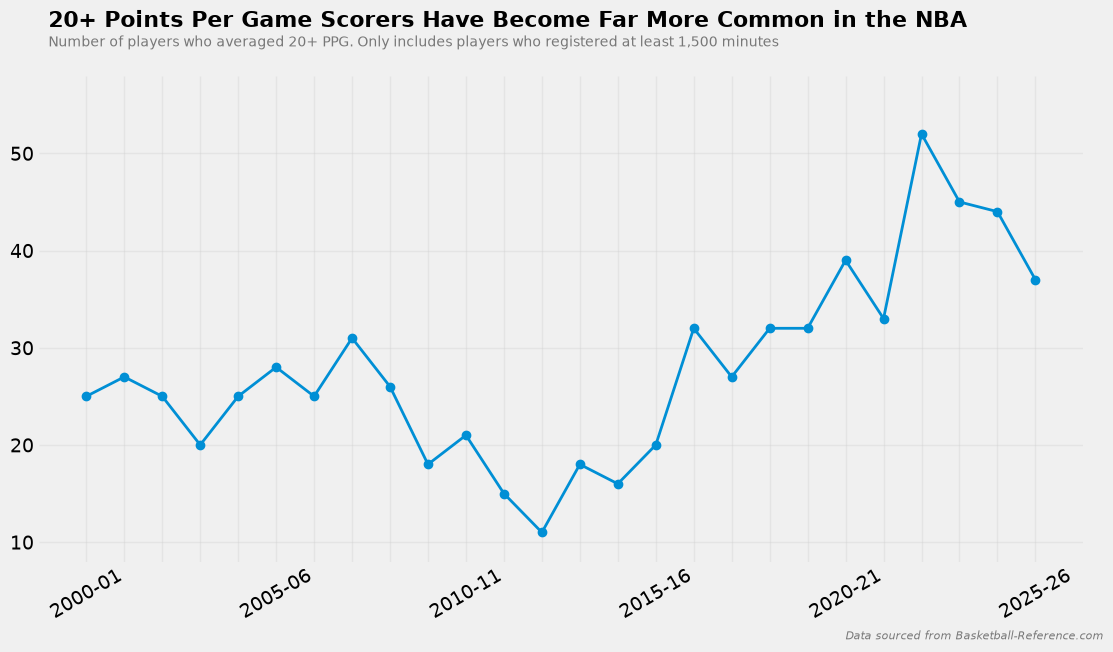

In [44]:
player_counts = twenty_ppg_df.groupby('season_end_year').size().sort_index()

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(player_counts.index, player_counts.values, marker='o', linewidth=2)
ax.set_xticks([2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026])
ax.set_xticklabels(
    [
        f'{year - 1}-{year % 100:02}' if year in {2001, 2006, 2011, 2016, 2021, 2026} else ''
        for year in ax.get_xticks()
    ],
    rotation=30
)
ax.set_ylim([8, 58])
ax.set_yticks([10, 20, 30, 40, 50])
ax.text(2000, 63, '20+ Points Per Game Scorers Have Become Far More Common in the NBA', fontsize=16, fontweight='bold')
ax.text(2000, 61, 'Number of players who averaged 20+ PPG. Only includes players who registered at least 1,500 minutes', fontsize=10, alpha=0.5)
ax.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
ax.tick_params(left=False, bottom=False)
ax.grid(axis='y', alpha=0.3)
ax.grid(axis='x', alpha=0.3)
ax.text(2021, 0, 'Data sourced from Basketball-Reference.com', fontsize=8, alpha=0.5, style='italic')

plt.show()


In [45]:
player_counts

season_end_year
2001    25
2002    27
2003    25
2004    20
2005    25
2006    28
2007    25
2008    31
2009    26
2010    18
2011    21
2012    15
2013    11
2014    18
2015    16
2016    20
2017    32
2018    27
2019    32
2020    32
2021    39
2022    33
2023    52
2024    45
2025    44
2026    37
dtype: int64

In [46]:
conn = sqlite3.connect('../data/nba_stats.db')

query = '''
SELECT g.season_end_year, g.per_game_pts, a.off_rating, a.ts_pct
FROM nba_per_game_averages AS g
JOIN nba_advanced_averages AS a
ON g.season_end_year = a.season_end_year
'''
team_averages_df = pd.read_sql_query(query, conn)
conn.close()

In [47]:
'team_averages_df' in dir()

True

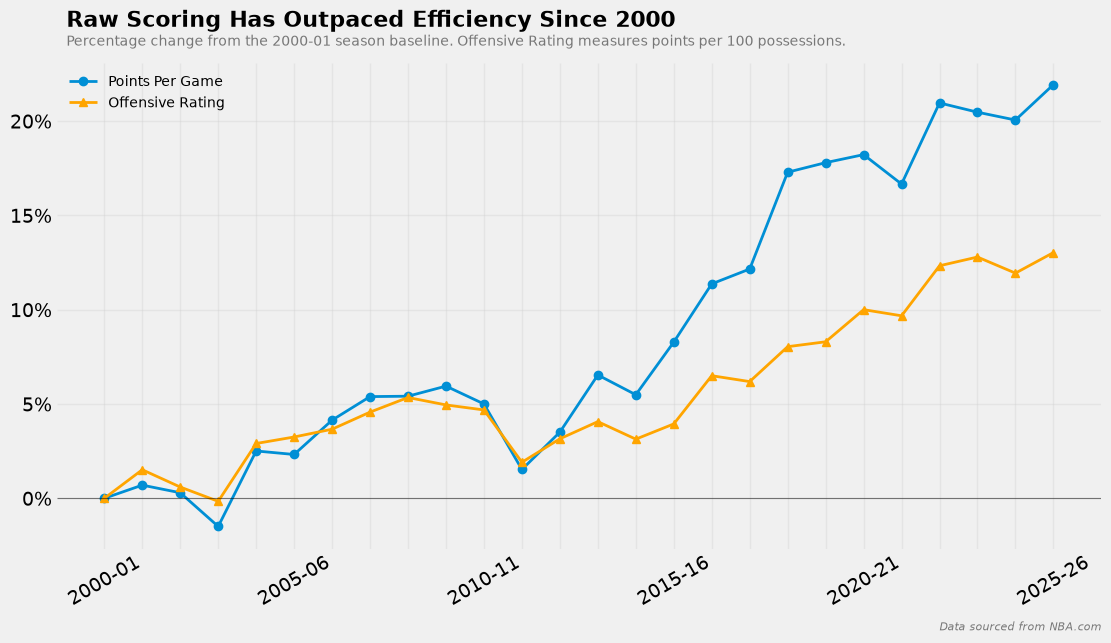

In [48]:
pts_base = team_averages_df['per_game_pts'].iloc[0]
rating_base = team_averages_df['off_rating'].iloc[0]

pts_pct_change = (team_averages_df['per_game_pts'] / pts_base - 1) * 100
rating_pct_change = (team_averages_df['off_rating'] / rating_base - 1) * 100

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(team_averages_df['season_end_year'], pts_pct_change, marker='o', linewidth=2)
ax.plot(team_averages_df['season_end_year'], rating_pct_change, marker='^', linewidth=2, color='orange')
ax.set_xticks([2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026])
ax.set_xticklabels(
    [
        f'{year - 1}-{year % 100:02}' if year in {2001, 2006, 2011, 2016, 2021, 2026} else ''
        for year in ax.get_xticks()
    ],
    rotation=30
)
ax.axhline(0, color='black', linewidth=0.8, alpha=0.5)
ax.yaxis.set_major_formatter(lambda y, _: f'{y:.0f}%')
ax.text(2000, 25, 'Raw Scoring Has Outpaced Efficiency Since 2000', fontsize=16, fontweight='bold')
ax.text(2000, 24, 'Percentage change from the 2000-01 season baseline. Offensive Rating measures points per 100 possessions.', fontsize=10, alpha=0.5)
ax.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
ax.tick_params(left=False, bottom=False)
ax.grid(axis='y', alpha=0.3)
ax.grid(axis='x', alpha=0.3)
ax.text(2023, -7, 'Data sourced from NBA.com', fontsize=8, alpha=0.5, style='italic')
ax.legend(['Points Per Game', 'Offensive Rating'], loc='upper left', fontsize=10, frameon=False)

plt.show()

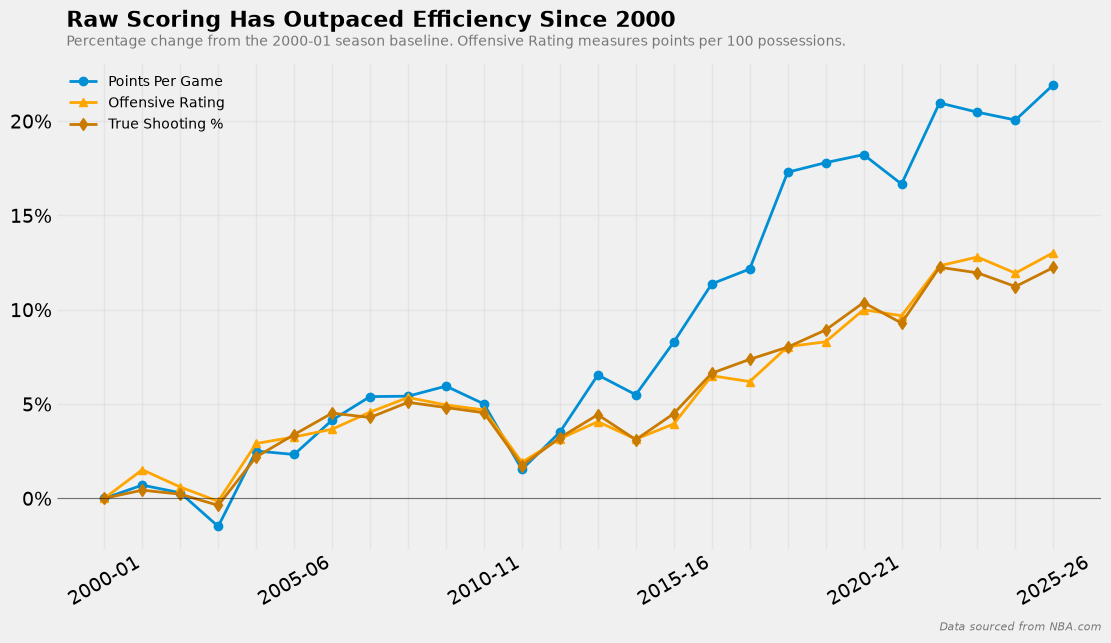

In [49]:
pts_base = team_averages_df['per_game_pts'].iloc[0]
rating_base = team_averages_df['off_rating'].iloc[0]
ts_base = team_averages_df['ts_pct'].iloc[0]

pts_pct_change = (team_averages_df['per_game_pts'] / pts_base - 1) * 100
rating_pct_change = (team_averages_df['off_rating'] / rating_base - 1) * 100
ts_pct_change = (team_averages_df['ts_pct'] / ts_base - 1) * 100

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(team_averages_df['season_end_year'], pts_pct_change, marker='o', linewidth=2)
ax.plot(team_averages_df['season_end_year'], rating_pct_change, marker='^', linewidth=2, color='orange')
ax.plot(team_averages_df['season_end_year'], ts_pct_change, marker='d', linewidth=2, color="#C97A00")
ax.set_xticks([2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026])
ax.set_xticklabels(
    [
        f'{year - 1}-{year % 100:02}' if year in {2001, 2006, 2011, 2016, 2021, 2026} else ''
        for year in ax.get_xticks()
    ],
    rotation=30
)
ax.axhline(0, color='black', linewidth=0.8, alpha=0.5)
ax.yaxis.set_major_formatter(lambda y, _: f'{y:.0f}%')
ax.text(2000, 25, 'Raw Scoring Has Outpaced Efficiency Since 2000', fontsize=16, fontweight='bold')
ax.text(2000, 24, 'Percentage change from the 2000-01 season baseline. Offensive Rating measures points per 100 possessions.', fontsize=10, alpha=0.5)
ax.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
ax.tick_params(left=False, bottom=False)
ax.grid(axis='y', alpha=0.3)
ax.grid(axis='x', alpha=0.3)
ax.text(2023, -7, 'Data sourced from NBA.com', fontsize=8, alpha=0.5, style='italic')
ax.legend(['Points Per Game', 'Offensive Rating', 'True Shooting %'], loc='upper left', fontsize=10, frameon=False)

plt.show()

In [50]:
compare_df = player_profile_df[
    ((player_profile_df['slug'] == 'simonan01') & (player_profile_df['season_end_year'] == 2023))
    | ((player_profile_df['slug'] == 'parketo01') & (player_profile_df['season_end_year'] == 2013))
]
compare_df = compare_df.set_index('player_name')
compare_df

,team_name,team_abbreviation,team_id,season_end_year,season,slug,player_id,games_played,minutes_per_game,minutes_played,scoring_plus,pts_plus,ts_plus,per_100_pts,true_shooting_percentage,offensive_win_shares,offensive_box_plus_minus,age,positions,points_per_game,fg_percentage,three_point_percentage,ft_percentage,assists_per_game,offensive_rebounds_per_game,defensive_rebounds_per_game,total_rebounds_per_game,turnovers_per_game,steals_per_game,blocks_per_game,stocks_per_game,per_100_reb,per_100_ast,per_100_stl,per_100_blk,per_100_tov,qualified,qualified_ast,pct_uast_fgm,uast_bin,uast_rating,profile
player_name,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Tony Parker,SAN ANTONIO SPURS,SAS,1610612759,2013,2012-2013,parketo01,2225,66,32.939394,2174,117.804777,148.434517,109.906542,31.1,0.588,7.1,4.1,30,POINT GUARD,20.318182,0.521608,0.352941,0.845455,7.560606,0.272727,2.727273,3.000000,2.575758,0.818182,0.090909,0.909091,4.6,11.6,1.3,0.1,3.9,1,1,0.723,9,4,Creator
Anfernee Simons,PORTLAND TRAIL BLAZERS,POR,1610612757,2023,2022-2023,simonan01,1629014,62,35.016129,2171,105.646890,127.545803,100.000000,29.1,0.581,2.1,1.3,23,SHOOTING GUARD,21.064516,0.446890,0.377224,0.893855,4.080645,0.290323,2.306452,2.596774,2.064516,0.677419,0.225806,0.903226,3.6,5.6,0.9,0.3,2.9,1,1,0.531,6,1,Balanced


In [51]:
parker_img = mpimg.imread('../docs/images/parker_cutout.png')
simons_img = mpimg.imread('../docs/images/simons_cutout.png')

/var/folders/0v/2wg9jwl91xn2qrb4vdq78mb40000gn/T/ipykernel_62364/2190156822.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


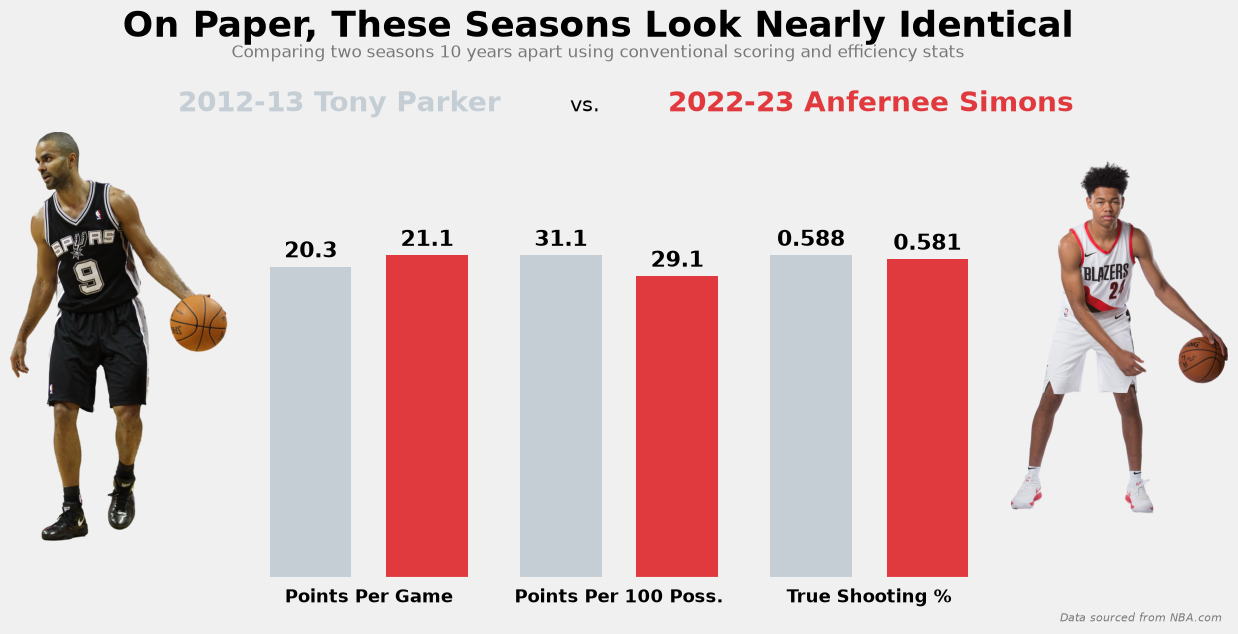

In [52]:
parker_row = compare_df.loc['Tony Parker']
simons_row = compare_df.loc['Anfernee Simons']

parker_vals = [parker_row['points_per_game'], parker_row['true_shooting_percentage'], parker_row['per_100_pts']]
simons_vals = [simons_row['points_per_game'], simons_row['true_shooting_percentage'], simons_row['per_100_pts']]

ppg_vals = [parker_row['points_per_game'], simons_row['points_per_game']]
ts_vals = [parker_row['true_shooting_percentage'], simons_row['true_shooting_percentage']]
pp100_vals = [parker_row['per_100_pts'], simons_row['per_100_pts']]

fig = plt.figure(figsize=(14, 6))

# 5 columns: [Parker photo | PPG panel | PP100 panel | TS% panel | Simons photo]
# width_ratios controls how much horizontal space each gets
gs = gridspec.GridSpec(1, 5, width_ratios=[1.5, 1.5, 1.5, 1.5, 1.5], wspace=0.15)

ax_img_left = fig.add_subplot(gs[0])
ax_ppg = fig.add_subplot(gs[1])
ax_pp100 = fig.add_subplot(gs[2])
ax_ts = fig.add_subplot(gs[3])
ax_img_right = fig.add_subplot(gs[4])

# Left image (Parker)
ax_img_left.imshow(parker_img)
ax_img_left.axis('off')

# Right image (Simons)
ax_img_right.imshow(simons_img)
ax_img_right.axis('off')

# --- PPG panel ---
bars = ax_ppg.bar(['Tony Parker', 'Anfernee Simons'], ppg_vals, width=0.7, color=['#C4CED4', '#E03A3E'])
ax_ppg.bar_label(bars, fmt='%.1f', padding=3, fontweight='bold', fontsize=16)
ax_ppg.set_ylim(0, max(ppg_vals) * 1.5)
ax_ppg.set_xlabel('Points Per Game', fontsize=13, fontweight='bold', labelpad=3)
ax_ppg.set_xticklabels([])
ax_ppg.spines[['top', 'right', 'left']].set_visible(False)
ax_ppg.tick_params(left=False, bottom=False)
ax_ppg.set_yticks([])
ax_ppg.grid(False)

# --- TS% panel ---
bars = ax_ts.bar(['Tony Parker', 'Anfernee Simons'], ts_vals, width=0.7, color=['#C4CED4', '#E03A3E'])
ax_ts.bar_label(bars, fmt='%.3f', padding=3, fontweight='bold', fontsize=16)
ax_ts.set_ylim(0, max(ts_vals) * 1.5)
ax_ts.set_xlabel('True Shooting %', fontsize=13, fontweight='bold', labelpad=3)
ax_ts.set_xticklabels([])
ax_ts.spines[['top', 'right', 'left']].set_visible(False)
ax_ts.tick_params(left=False, bottom=False)
ax_ts.set_yticks([])
ax_ts.grid(False)

# --- PP100 panel ---
bars = ax_pp100.bar(['Tony Parker', 'Anfernee Simons'], pp100_vals, width=0.7, color=['#C4CED4', '#E03A3E'])
ax_pp100.bar_label(bars, fmt='%.1f', padding=3, fontweight='bold', fontsize=16)
ax_pp100.set_ylim(0, max(pp100_vals) * 1.5)
ax_pp100.set_xlabel('Points Per 100 Poss.', fontsize=13, fontweight='bold', labelpad=3)
ax_pp100.set_xticklabels([])
ax_pp100.spines[['top', 'right', 'left']].set_visible(False)
ax_pp100.tick_params(left=False, bottom=False)
ax_pp100.set_yticks([])
ax_pp100.grid(False)

fig.suptitle('On Paper, These Seasons Look Nearly Identical', fontsize=26, fontweight='bold', x=0.5, ha='center', y=1.02)
fig.text(0.5, 0.94, 'Comparing two seasons 10 years apart using conventional scoring and efficiency stats', fontsize=12, alpha=0.5, ha='center')
fig.text(0.2, 0.85, '2012-13 Tony Parker', fontsize=20, color='#C4CED4', fontweight='bold')
fig.text(0.55, 0.85, '2022-23 Anfernee Simons', fontsize=20, color='#E03A3E', fontweight='bold')
fig.text(0.48, 0.85, 'vs.', fontsize=15)
fig.text(0.83, 0, 'Data sourced from NBA.com', fontsize=8, alpha=0.5, style='italic')

plt.tight_layout()
plt.show()

In [53]:
conn = sqlite3.connect('../data/nba_stats.db')

query = '''
SELECT * 
FROM player_profile 
WHERE season_end_year = 2023 AND qualified = 1
'''
season_2023_df = pd.read_sql_query(query, conn)
season_2023_df = season_2023_df.set_index('player_name')

query = '''
SELECT *
FROM player_profile
WHERE season_end_year = 2013 AND qualified = 1
'''
season_2013_df = pd.read_sql_query(query, conn)
season_2013_df = season_2013_df.set_index('player_name')
conn.close()

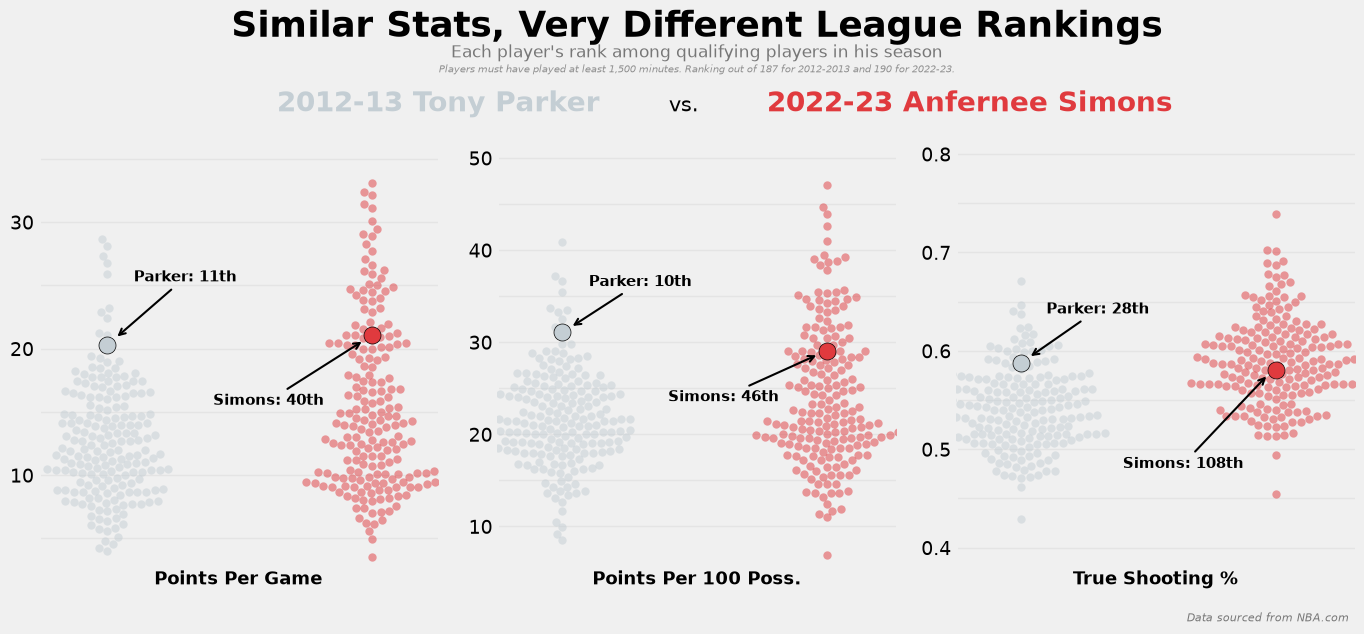

In [54]:
parker_row = season_2013_df.loc['Tony Parker']
simons_row = season_2023_df.loc['Anfernee Simons']

parker_vals = [parker_row['points_per_game'], parker_row['true_shooting_percentage'], parker_row['per_100_pts']]
simons_vals = [simons_row['points_per_game'], simons_row['true_shooting_percentage'], simons_row['per_100_pts']]

ppg_vals = [parker_row['points_per_game'], simons_row['points_per_game']]
ts_vals = [parker_row['true_shooting_percentage'], simons_row['true_shooting_percentage']]
pp100_vals = [parker_row['per_100_pts'], simons_row['per_100_pts']]

fig = plt.figure(figsize=(14, 6))

# 3 columns: [ PPG panel | PP100 panel | TS% panel ]
# width_ratios controls how much horizontal space each gets
gs = gridspec.GridSpec(1, 3, width_ratios=[1.5, 1.5, 1.5], wspace=0.15)

ax_ppg = fig.add_subplot(gs[0])
ax_pp100 = fig.add_subplot(gs[1])
ax_ts = fig.add_subplot(gs[2])


# --- Reusable function to build one beeswarm panel ---
def swarm_panel(ax, league_2013_vals, league_2023_vals, parker_val, simons_val, stat_label):
    sns.swarmplot(x=[0]*len(league_2013_vals), y=league_2013_vals, ax=ax,
                  color='#C4CED4', size=6, alpha=0.5)
    sns.swarmplot(x=[1]*len(league_2023_vals), y=league_2023_vals, ax=ax,
                  color='#E03A3E', size=6, alpha=0.5)

    ax.scatter(0, parker_val, color='#C4CED4', s=150, zorder=5, marker='o', edgecolor='black')
    ax.scatter(1, simons_val, color='#E03A3E', s=150, zorder=5, marker='o', edgecolor='black')

    ax.set_xticks([0, 1])
    ax.set_xticklabels('')
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_ylabel('')
    ax.set_ylim(min(min(league_2013_vals), min(league_2023_vals)) * 0.9,
                max(max(league_2013_vals), max(league_2023_vals)) * 1.1)
    ax.grid(axis='y', alpha=0.3)

# --- Build each panel ---
swarm_panel(ax_ppg, season_2013_df['points_per_game'], season_2023_df['points_per_game'],
            parker_row['points_per_game'], simons_row['points_per_game'], 'Points Per Game')
ax_ppg.set_xlabel('Points Per Game', fontsize=13, fontweight='bold', labelpad=3)
ax_ppg.set_yticks([5, 10, 15, 20, 25, 30, 35])
ax_ppg.set_yticklabels(['', '10', '', '20', '', '30', ''])
ax_ppg.annotate('Parker: 11th', 
            xy=(0.03, parker_row['points_per_game']+0.5),
            xytext=(0.1, parker_row['points_per_game'] + 5),
            fontsize=11, color='black', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='black', lw=1.5))

ax_ppg.annotate('Simons: 40th', 
            xy=(0.97, simons_row['points_per_game']-0.4),
            xytext=(0.4, simons_row['points_per_game'] - 5.5),
            fontsize=11, color='black', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='black', lw=1.5))

swarm_panel(ax_pp100, season_2013_df['per_100_pts'], season_2023_df['per_100_pts'],
            parker_row['per_100_pts'], simons_row['per_100_pts'], 'Points Per 100 Poss.')
ax_pp100.set_xlabel('Points Per 100 Poss.', fontsize=13, fontweight='bold', labelpad=3)
ax_pp100.set_yticks([10, 15, 20, 25, 30, 35, 40, 45, 50])
ax_pp100.set_yticklabels(['10', '', '20', '', '30', '', '40', '', '50'])
ax_pp100.annotate('Parker: 10th', 
            xy=(0.03, parker_row['per_100_pts']+0.5),
            xytext=(0.1, parker_row['per_100_pts'] + 5),
            fontsize=11, color='black', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='black', lw=1.5))

ax_pp100.annotate('Simons: 46th', 
            xy=(0.97, simons_row['per_100_pts']-0.4),
            xytext=(0.4, simons_row['per_100_pts'] - 5.5),
            fontsize=11, color='black', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='black', lw=1.5))

swarm_panel(ax_ts, season_2013_df['true_shooting_percentage'], season_2023_df['true_shooting_percentage'],
            parker_row['true_shooting_percentage'], simons_row['true_shooting_percentage'], 'True Shooting %')
ax_ts.set_xlabel('True Shooting %', fontsize=13, fontweight='bold', labelpad=3)
ax_ts.set_yticks([0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8])
ax_ts.set_yticklabels(['0.4', '', '0.5', '', '0.6', '', '0.7', '', '0.8'])
ax_ts.annotate('Parker: 28th', 
            xy=(0.03, parker_row['true_shooting_percentage'] + 0.005),
            xytext=(0.1, parker_row['true_shooting_percentage'] + 0.05),
            fontsize=11, color='black', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='black', lw=1.5))

ax_ts.annotate('Simons: 108th', 
            xy=(0.97, simons_row['true_shooting_percentage']-0.005),
            xytext=(0.4, simons_row['true_shooting_percentage'] - 0.1),
            fontsize=11, color='black', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='black', lw=1.5))


fig.suptitle('Similar Stats, Very Different League Rankings', fontsize=26, fontweight='bold', x=0.5, ha='center', y=1.02)
fig.text(0.5, 0.94, "Each player's rank among qualifying players in his season", fontsize=12, alpha=0.5, ha='center')
fig.text(0.5, 0.915, 'Players must have played at least 1,500 minutes. Ranking out of 187 for 2012-2013 and 190 for 2022-23.', fontsize=7, alpha=0.4, style='italic', ha='center')
fig.text(0.2, 0.85, '2012-13 Tony Parker', fontsize=20, color='#C4CED4', fontweight='bold')
fig.text(0.55, 0.85, '2022-23 Anfernee Simons', fontsize=20, color='#E03A3E', fontweight='bold')
fig.text(0.48, 0.85, 'vs.', fontsize=15)
fig.text(0.85, 0, 'Data sourced from NBA.com', fontsize=8, alpha=0.5, style='italic')

fig.subplots_adjust(top=0.8, bottom=0.1, left=0.03, right=0.97, wspace=0.15)
plt.show()

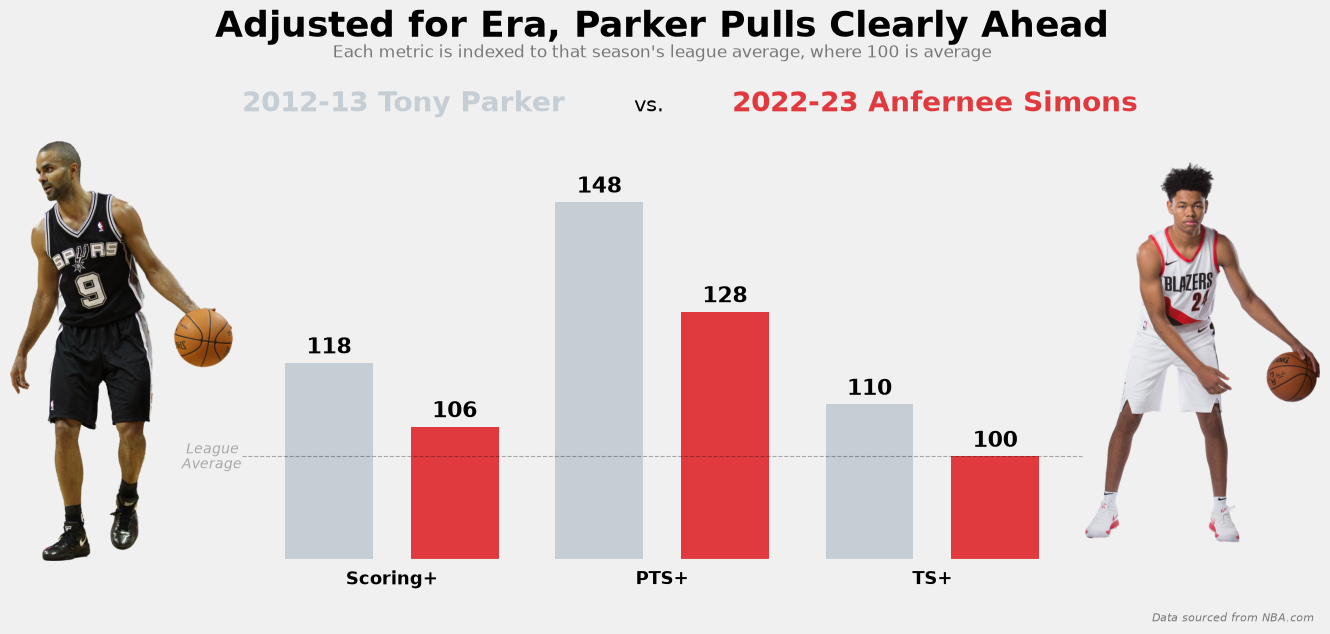

In [55]:
parker_row = compare_df.loc['Tony Parker']
simons_row = compare_df.loc['Anfernee Simons']

parker_vals = [parker_row['scoring_plus'], parker_row['ts_plus'], parker_row['pts_plus']]
simons_vals = [simons_row['scoring_plus'], simons_row['ts_plus'], simons_row['pts_plus']]

scoring_plus_vals = [parker_row['scoring_plus'], simons_row['scoring_plus']]
ts_plus_vals = [parker_row['ts_plus'], simons_row['ts_plus']]
pts_plus_vals = [parker_row['pts_plus'], simons_row['pts_plus']]

fig = plt.figure(figsize=(14, 6))

# 5 columns: [Parker photo | PPG panel | PP100 panel | TS% panel | Simons photo]
# width_ratios controls how much horizontal space each gets
gs = gridspec.GridSpec(1, 5, width_ratios=[1.5, 1.5, 1.5, 1.5, 1.5], wspace=0.15)

ax_img_left = fig.add_subplot(gs[0])
ax_scoring = fig.add_subplot(gs[1])
ax_pts_plus = fig.add_subplot(gs[2])
ax_ts_plus = fig.add_subplot(gs[3])
ax_img_right = fig.add_subplot(gs[4])

# Left image (Parker)
ax_img_left.imshow(parker_img)
ax_img_left.axis('off')

# Right image (Simons)
ax_img_right.imshow(simons_img)
ax_img_right.axis('off')

# --- Scoring+ panel ---
bars = ax_scoring.bar(['Tony Parker', 'Anfernee Simons'], scoring_plus_vals, width=0.7, color=['#C4CED4', '#E03A3E'])
ax_scoring.bar_label(bars, fmt='%.0f', padding=3, fontweight='bold', fontsize=16)
ax_scoring.set_ylim(80, 160)
ax_scoring.set_xlabel('Scoring+', fontsize=13, fontweight='bold', labelpad=3)
ax_scoring.set_xticklabels([])
ax_scoring.spines[['top', 'right', 'left']].set_visible(False)
ax_scoring.tick_params(left=False, bottom=False)
ax_scoring.set_yticks([])
ax_scoring.grid(False)

# --- TS+ panel ---
bars = ax_ts_plus.bar(['Tony Parker', 'Anfernee Simons'], ts_plus_vals, width=0.7, color=['#C4CED4', '#E03A3E'])
ax_ts_plus.bar_label(bars, fmt='%.0f', padding=3, fontweight='bold', fontsize=16)
ax_ts_plus.set_ylim(80, 160)
ax_ts_plus.set_xlabel('TS+', fontsize=13, fontweight='bold', labelpad=3)
ax_ts_plus.set_xticklabels([])
ax_ts_plus.spines[['top', 'right', 'left']].set_visible(False)
ax_ts_plus.tick_params(left=False, bottom=False)
ax_ts_plus.set_yticks([])
ax_ts_plus.grid(False)

# --- PTS+ panel ---
bars = ax_pts_plus.bar(['Tony Parker', 'Anfernee Simons'], pts_plus_vals, width=0.7, color=['#C4CED4', '#E03A3E'])
ax_pts_plus.bar_label(bars, fmt='%.0f', padding=3, fontweight='bold', fontsize=16)
ax_pts_plus.set_ylim(80, 160)
ax_pts_plus.set_xlabel('PTS+', fontsize=13, fontweight='bold', labelpad=3)
ax_pts_plus.set_xticklabels([])
ax_pts_plus.spines[['top', 'right', 'left']].set_visible(False)
ax_pts_plus.tick_params(left=False, bottom=False)
ax_pts_plus.set_yticks([])
ax_pts_plus.grid(False)

fig.suptitle('Adjusted for Era, Parker Pulls Clearly Ahead', fontsize=26, fontweight='bold', x=0.5, ha='center', y=1.02)
fig.text(0.5, 0.94, "Each metric is indexed to that season's league average, where 100 is average", fontsize=12, alpha=0.5, ha='center')
fig.text(0.2, 0.85, '2012-13 Tony Parker', fontsize=20, color='#C4CED4', fontweight='bold')
fig.text(0.55, 0.85, '2022-23 Anfernee Simons', fontsize=20, color='#E03A3E', fontweight='bold')
fig.text(0.48, 0.85, 'vs.', fontsize=15)
fig.text(0.85, 0, 'Data sourced from NBA.com', fontsize=8, alpha=0.5, style='italic')
fig.text(0.16, 0.28, 'League', fontsize=10, alpha=0.3, color='black', style='italic')
fig.text(0.157, 0.255, 'Average', fontsize=10, alpha=0.3, color='black', style='italic')

avg_line = plt.Line2D([0.2,0.8], [0.275, 0.275], color='black', linestyle='--', linewidth=0.8, alpha=0.3, transform=fig.transFigure)
fig.add_artist(avg_line)

fig.subplots_adjust(top=0.8, bottom=0.1, left=0.03, right=0.97, wspace=0.15)
plt.show()

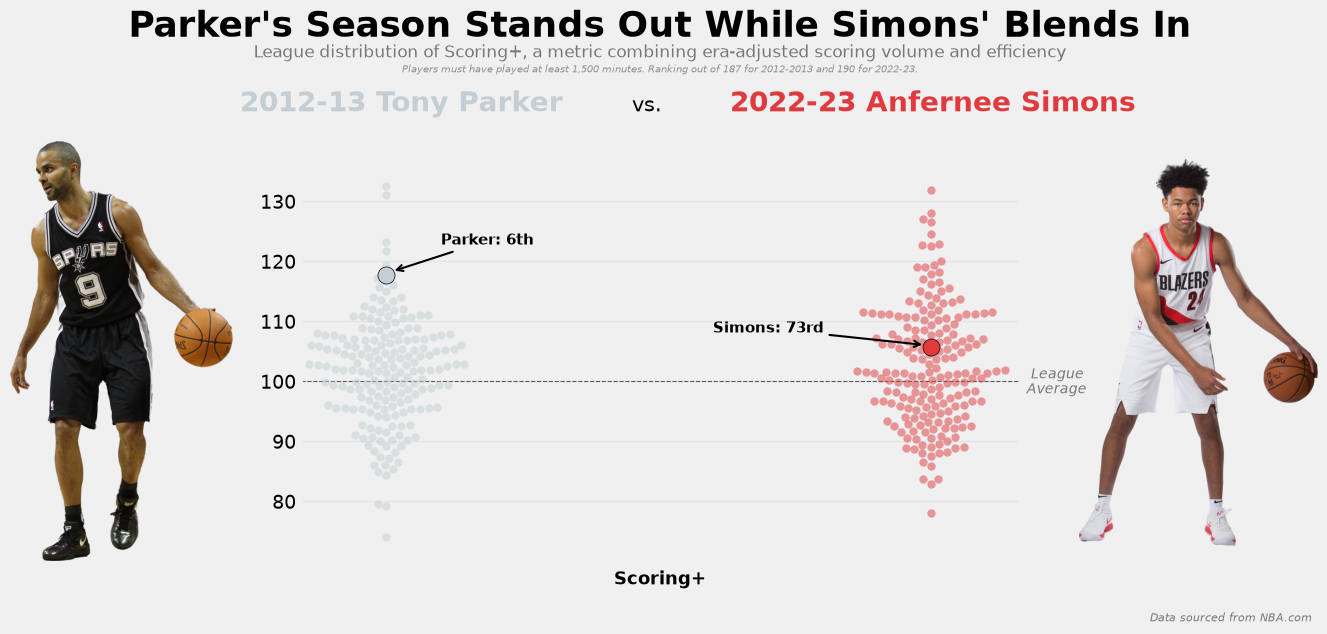

In [56]:
fig = plt.figure(figsize=(14, 6))

# 3 columns: [Parker Photo | PP100 panel | Simons Photo]
# width_ratios controls how much horizontal space each gets
gs = gridspec.GridSpec(1, 3, width_ratios=[1.5, 4.5, 1.5], wspace=0.15)

ax_img_left = fig.add_subplot(gs[0])
ax_scoring = fig.add_subplot(gs[1])
ax_img_right = fig.add_subplot(gs[2])

# Left image (Parker)
ax_img_left.imshow(parker_img)
ax_img_left.axis('off')

# Right image (Simons)
ax_img_right.imshow(simons_img)
ax_img_right.axis('off')


# --- Build the graph ---
swarm_panel(ax_scoring, season_2013_df['scoring_plus'], season_2023_df['scoring_plus'],
            parker_row['scoring_plus'], simons_row['scoring_plus'], 'Scoring+')
ax_scoring.set_xlabel('Scoring+', fontsize=13, fontweight='bold', labelpad=3)
ax_scoring.set_ylim([70,140])
ax_scoring.set_yticks([80, 90, 100, 110, 120, 130])
ax_scoring.set_yticklabels(['80', '90', '100', '110', '120', '130'])
ax_scoring.annotate('Parker: 6th', 
            xy=(0.01, parker_row['scoring_plus']+0.5),
            xytext=(0.1, parker_row['scoring_plus'] + 5),
            fontsize=11, color='black', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='black', lw=1.5))

ax_scoring.annotate('Simons: 73rd', 
            xy=(0.99, simons_row['scoring_plus']+0.4),
            xytext=(0.6, simons_row['scoring_plus'] + 2.5),
            fontsize=11, color='black', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='black', lw=1.5))
ax_scoring.axhline(y=100, linestyle='--', color='black', alpha=0.6, linewidth=0.8, zorder=1)


fig.suptitle("Parker's Season Stands Out While Simons' Blends In", fontsize=26, fontweight='bold', x=0.5, ha='center', y=1.02)
fig.text(0.5, 0.94, "League distribution of Scoring+, a metric combining era-adjusted scoring volume and efficiency", fontsize=12, alpha=0.5, ha='center')
fig.text(0.5, 0.915, 'Players must have played at least 1,500 minutes. Ranking out of 187 for 2012-2013 and 190 for 2022-23.', fontsize=7, alpha=0.4, style='italic', ha='center')
fig.text(0.2, 0.85, '2012-13 Tony Parker', fontsize=20, color='#C4CED4', fontweight='bold')
fig.text(0.55, 0.85, '2022-23 Anfernee Simons', fontsize=20, color='#E03A3E', fontweight='bold')
fig.text(0.48, 0.85, 'vs.', fontsize=15)
fig.text(0.85, 0, 'Data sourced from NBA.com', fontsize=8, alpha=0.5, style='italic')
fig.text(0.765, 0.405, 'League', fontsize=10, alpha=0.5, color='black', style='italic')
fig.text(0.762, 0.38, 'Average', fontsize=10, alpha=0.5, color='black', style='italic')

fig.subplots_adjust(top=0.8, bottom=0.1, left=0.03, right=0.97, wspace=0.15)
plt.show()

In [57]:
conn = sqlite3.connect('../data/nba_stats.db')

query = '''
SELECT * 
FROM player_profile
WHERE qualified = 1
'''
q_player_profile_df = pd.read_sql_query(query, conn)
conn.close()

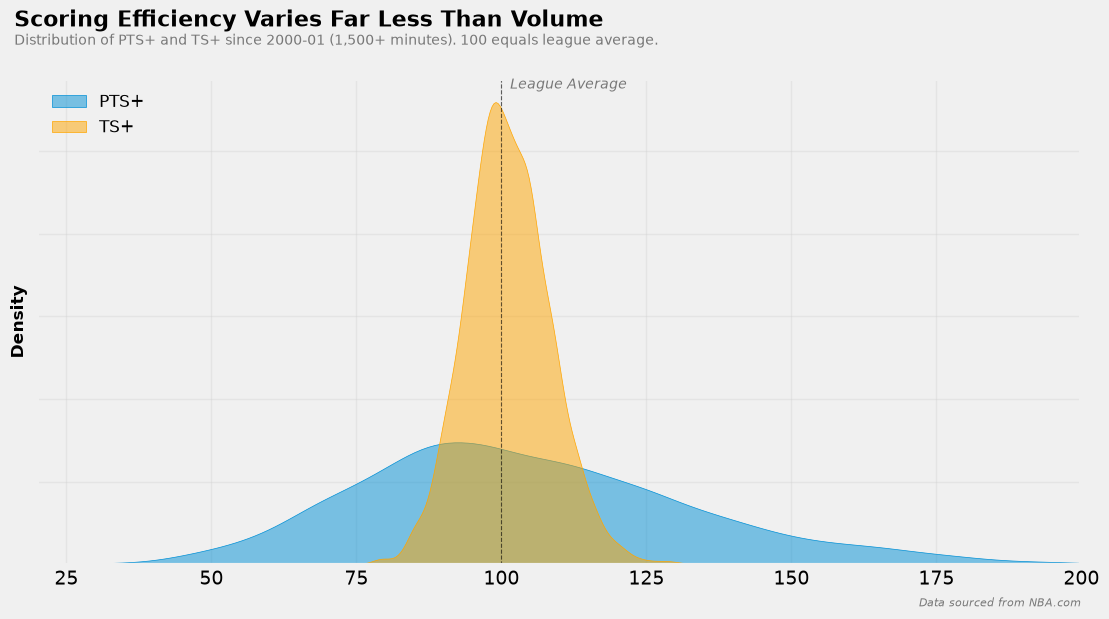

In [58]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.kdeplot(
    data=q_player_profile_df['pts_plus'],
    fill=True,
    alpha=0.5,
    label='PTS+'
)

sns.kdeplot(
    data=q_player_profile_df['ts_plus'],
    fill=True,
    alpha=0.5,
    label='TS+',
    color='orange'
)

plt.grid(alpha=0.3)
plt.xlabel('')
plt.xlim([20,200])
plt.xticks([25, 50, 75, 100, 125, 150, 175, 200])
plt.yticks([0, 0.01, 0.02, 0.03, 0.04, 0.05], ['', '', '', '', '', ''])
plt.ylabel('Density', fontsize=12, fontweight='bold')
plt.axvline(x=100, linestyle='--', color='black', alpha=0.6, linewidth=0.8)
plt.text(16, 0.065, 'Scoring Efficiency Varies Far Less Than Volume', fontsize=16, fontweight='bold')
plt.text(16, 0.0628, 'Distribution of PTS+ and TS+ since 2000-01 (1,500+ minutes). 100 equals league average.', fontsize=10, alpha=0.5)
plt.text(101.5, 0.0575, 'League Average', fontsize=10, alpha=0.5, color='black', style='italic')
ax.text(172, -0.005, 'Data sourced from NBA.com', fontsize=8, alpha=0.5, style='italic')
plt.legend(loc='upper left', fontsize=12, frameon=False)

plt.show()

# Team Charts

In [59]:
conn = sqlite3.connect('../data/nba_stats.db')

query = 'SELECT * FROM team_colors'
team_colors_df = pd.read_sql_query(query, conn)
conn.close()

team_colors_df.head()

,team_name,color_1_hex,color_1_general,color_2_hex,color_2_general,team_id,Unnamed: 6
0,Boston Celtics,#007A33,Green,#BA9653,Beige,1610612738,None
1,Brooklyn Nets,#000000,Black,#FFFFFF,White,1610612751,None
2,New York Knicks,#006BB6,Blue,#F58426,Orange,1610612752,None
3,Philadelphia 76ers,#006BB6,Blue,#ED174C,Red,1610612755,None
4,Toronto Raptors,#CE1141,Red,#000000,Black,1610612761,None


In [60]:
team_color_map = dict(zip(team_colors_df['team_name'], team_colors_df['color_1_hex']))
team_color_map['San Antonio Spurs'] = '#000000'

In [61]:
team_profile_df.head()

,season_end_year,team_id,team_name,gp,w,l,w_pct,off_rating,ast_pct,pct_uast_fgm,ts_pct,league_off_rating,league_ast_pct,league_pct_uast_fgm,league_ts_pct,team_orating_plus,team_ts_plus,team_possession_residual,team_possession_plus,oreb_pct,tm_tov_pct,team_orating_plus_rank,team_ts_plus_rank,team_possession_plus_rank,pct_uast_fgm_rank,oreb_pct_rank,tm_tov_pct_rank,team_fg_pct,team_3pt_pct,team_ft_pct,team_ppg,finishers,balanced,creators,finishers_q,balanced_q,creators_q
0,2001,1610612737,Atlanta Hawks,82,25,57,0.305,96.9,0.542,0.458,0.500,101.555172,0.610069,0.389931,0.518034,95.416115,96.518671,-1.713859,98.286141,0.313,0.178,27,26,25,29,15,28,0.431,0.357,0.759,91.0,7,4,5,0,2,2
1,2001,1610612738,Boston Celtics,82,36,46,0.439,100.1,0.616,0.384,0.521,101.555172,0.610069,0.389931,0.518034,98.567111,100.572456,-1.904824,98.095176,0.280,0.166,17,12,27,12,26,20,0.428,0.363,0.740,94.6,8,3,4,2,2,1
2,2001,1610612766,Charlotte Hornets,82,46,36,0.561,99.7,0.679,0.321,0.506,101.555172,0.610069,0.389931,0.518034,98.173237,97.676895,0.088417,100.088417,0.315,0.156,19,23,13,2,13,10,0.431,0.346,0.745,91.9,12,2,1,3,1,1
3,2001,1610612741,Chicago Bulls,82,15,67,0.183,95.9,0.665,0.335,0.495,101.555172,0.610069,0.389931,0.518034,94.431428,95.553485,-1.902840,98.097160,0.302,0.173,29,28,26,3,20,25,0.424,0.346,0.739,87.6,7,6,3,3,2,0
4,2001,1610612739,Cleveland Cavaliers,82,30,52,0.366,99.3,0.591,0.409,0.509,101.555172,0.610069,0.389931,0.518034,97.779362,98.256007,-0.782881,99.217119,0.331,0.177,22,22,20,19,7,27,0.442,0.334,0.765,92.2,6,5,7,1,3,2


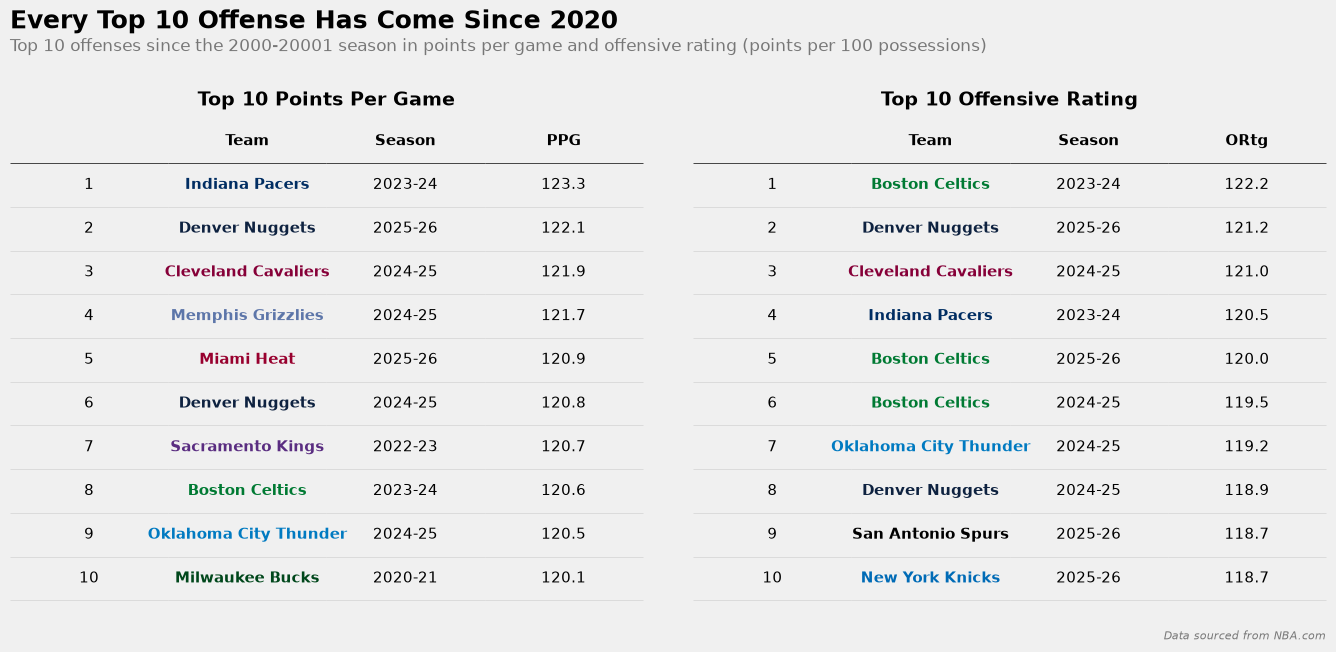

In [62]:
top_10_ppg = team_profile_df.sort_values(by='team_ppg', ascending=False).head(10)
top_10_orating = team_profile_df.sort_values(by='off_rating', ascending=False).head(10)

TEAM_COL, SEASON_COL = 'team_name', 'season_end_year'
ppg_cols,     ppg_labels     = [TEAM_COL, SEASON_COL, 'team_ppg'],      ['Team', 'Season', 'PPG']
orating_cols, orating_labels = [TEAM_COL, SEASON_COL, 'off_rating'], ['Team', 'Season', 'ORtg']

def format_season(end_year):
    end_year = int(end_year)
    return f"{end_year - 1}-{str(end_year)[-2:]}"

def prep(df, cols):
    """Select columns, round floats, format season, and add a rank column."""
    out = df[cols].reset_index(drop=True).copy()
    if 'season_end_year' in out.columns:
        out['season_end_year'] = out['season_end_year'].map(format_season)
    for c in cols:
        if pd.api.types.is_float_dtype(out[c]):
            out[c] = out[c].map('{:.1f}'.format)
    out.insert(0, '#', range(1, len(out) + 1))
    return out


def draw_table(ax, raw_df, cols, labels, title, team_col='team_name', color_map=None):
    df = prep(raw_df, cols)
    ax.axis('off')
    tbl = ax.table(
        cellText=df.values,
        colLabels=[''] + labels,
        cellLoc='center',
        bbox=[0, 0, 1, 1],
    )
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(11)

    bg = ax.figure.get_facecolor()
    team_idx = cols.index(team_col) + 1   # +1 because of the rank column

    for (r, c), cell in tbl.get_celld().items():
        cell.set_facecolor(bg)
        if r == 0:  # header row
            cell.set_text_props(weight='bold')
            cell.set_edgecolor('black')
            cell.visible_edges = 'B'
        else:
            cell.set_edgecolor('lightgray')
            cell.visible_edges = 'B'
            if color_map and c == team_idx:
                team_name = cell.get_text().get_text()
                cell.set_text_props(color=color_map.get(team_name, 'black'),
                                    weight='bold')

    ax.set_title(title, loc='center', fontsize=14, fontweight='bold', pad=10)


fig, (ax_ppg, ax_ortg) = plt.subplots(1, 2, figsize=(14, 6.5))

draw_table(ax_ppg,  top_10_ppg,     ppg_cols,     ppg_labels,     'Top 10 Points Per Game', color_map = team_color_map)
draw_table(ax_ortg, top_10_orating, orating_cols, orating_labels, 'Top 10 Offensive Rating', color_map = team_color_map)

# Header and footer
fig.text(0.03, 0.96, 'Every Top 10 Offense Has Come Since 2020', fontsize=18, fontweight='bold', ha='left')
fig.text(0.03, 0.925, 'Top 10 offenses since the 2000-20001 season in points per game and offensive rating (points per 100 possessions)', fontsize=12, alpha=0.5, ha='left')
fig.text(0.97, 0.02, 'Data sourced from NBA.com', fontsize=8, alpha=0.5,
         style='italic', ha='right')

fig.subplots_adjust(top=0.82, bottom=0.08, left=0.03, right=0.97, wspace=0.08)
plt.show()

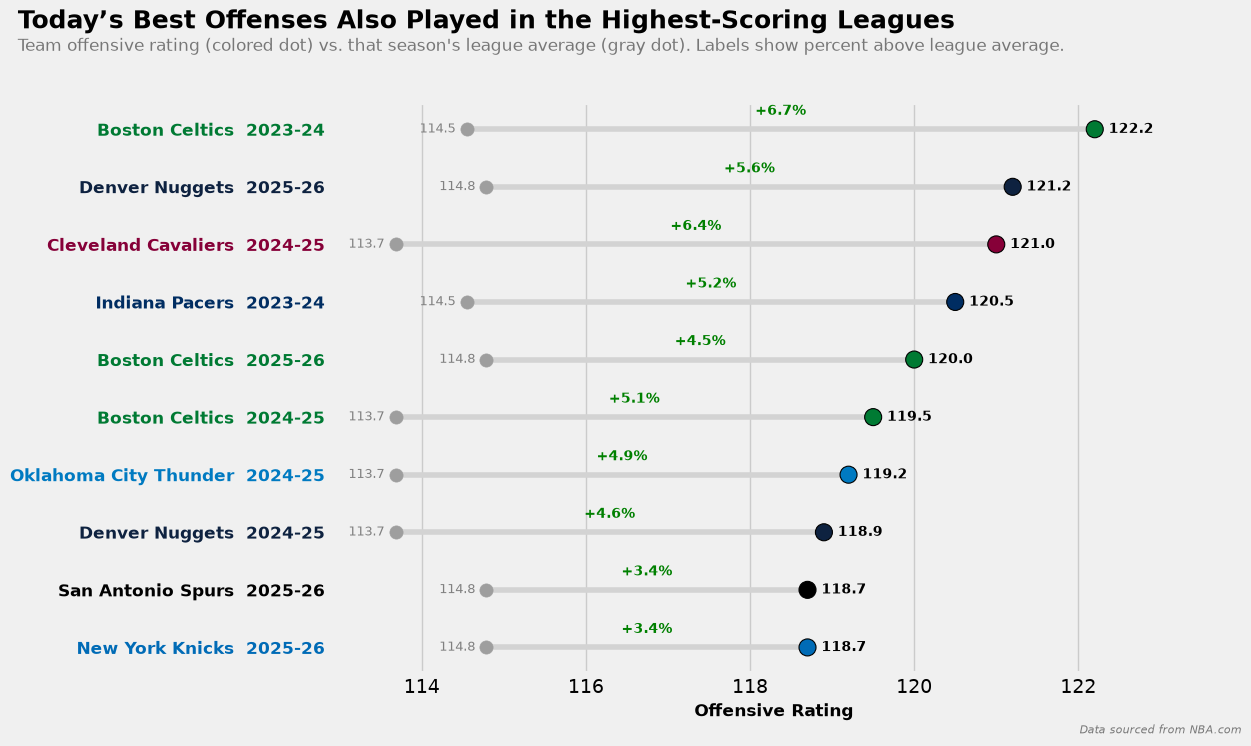

In [64]:
y = np.arange(len(top_10_orating))
team_colors = [team_color_map.get(t, '#555555') for t in top_10_orating['team_name']]
labels = [f"{t}  {format_season(s)}"
          for t, s in zip(top_10_orating['team_name'], top_10_orating['season_end_year'])]
LEAGUE_COLOR = '#9E9E9E'

fig, ax = plt.subplots(figsize=(12, 7.5))

# Dumbbell: league average -> team ORtg
ax.hlines(y, top_10_orating['league_off_rating'], top_10_orating['off_rating'],
          color='lightgray', lw=4, zorder=1)
ax.scatter(top_10_orating['league_off_rating'], y, color=LEAGUE_COLOR, s=90, zorder=2)
ax.scatter(top_10_orating['off_rating'], y, color=team_colors, s=150,
           edgecolor='black', linewidth=0.8, zorder=3)

for yi, (team_v, lg_v) in enumerate(zip(top_10_orating['off_rating'],
                                        top_10_orating['league_off_rating'])):
    ax.annotate(f'{team_v:.1f}', xy=(team_v, yi), xytext=(10, 0),
                textcoords='offset points', va='center', fontsize=10, fontweight='bold')
    ax.annotate(f'{lg_v:.1f}', xy=(lg_v, yi), xytext=(-8, 0),
                textcoords='offset points', va='center', ha='right', fontsize=9, color='gray')
    pct = (team_v - lg_v) / lg_v * 100
    mid_x = (team_v + lg_v) / 2
    ax.annotate(f'+{pct:.1f}%', xy=(mid_x, yi), xytext=(0, 8),
                    textcoords='offset points', ha='center', va='bottom',
                    fontsize=10, fontweight='bold', color='green')

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=12, fontweight='bold')
for tick_label, color in zip(ax.get_yticklabels(), team_colors):
    tick_label.set_color(color)

ax.invert_yaxis()   # best team at the top
ax.set_xlim(top_10_orating['league_off_rating'].min() - 0.8,
            top_10_orating['off_rating'].max() + 1.5)
ax.set_xlabel('Offensive Rating', fontsize=12, fontweight='bold')
ax.grid(axis='y', visible=False)

# Header and footer
fig.text(-0.04, 0.96, 'Today’s Best Offenses Also Played in the Highest-Scoring Leagues', fontsize=18, fontweight='bold', ha='left')
fig.text(-0.04, 0.93,
         "Team offensive rating (colored dot) vs. that season's league average (gray dot). Labels show percent above league average.",
         fontsize=12, alpha=0.5, ha='left')
fig.text(0.98, 0.02, 'Data sourced from NBA.com', fontsize=8, alpha=0.5,
         style='italic', ha='right')

fig.subplots_adjust(top=0.86, bottom=0.1, left=0.22, right=0.96)
plt.show()

In [66]:
top_10_orating_plus = team_profile_df.sort_values(by='team_orating_plus', ascending=False).head(10)
top_10_orating_plus

,season_end_year,team_id,team_name,gp,w,l,w_pct,off_rating,ast_pct,pct_uast_fgm,ts_pct,league_off_rating,league_ast_pct,league_pct_uast_fgm,league_ts_pct,team_orating_plus,team_ts_plus,team_possession_residual,team_possession_plus,oreb_pct,tm_tov_pct,team_orating_plus_rank,team_ts_plus_rank,team_possession_plus_rank,pct_uast_fgm_rank,oreb_pct_rank,tm_tov_pct_rank,team_fg_pct,team_3pt_pct,team_ft_pct,team_ppg,finishers,balanced,creators,finishers_q,balanced_q,creators_q
91,2004,1610612742,Dallas Mavericks,82,52,30,0.634,110.4,0.591,0.409,0.536,101.393103,0.608172,0.391828,0.516103,108.883145,103.855148,5.704941,105.704941,0.335,0.128,1,3,1,19,6,1,0.459,0.348,0.796,105.2,5,3,5,3,1,2
138,2005,1610612756,Phoenix Suns,82,62,20,0.756,112.7,0.575,0.425,0.571,104.506667,0.592233,0.407767,0.529400,107.840010,107.857952,1.361872,101.361872,0.304,0.140,1,1,7,22,23,2,0.477,0.393,0.748,110.4,6,3,5,3,1,2
455,2016,1610612744,Golden State Warriors,82,73,9,0.890,113.5,0.680,0.320,0.593,105.560000,0.582033,0.417967,0.541300,107.521789,109.551081,-0.352174,99.647826,0.267,0.150,1,1,18,1,22,17,0.487,0.416,0.763,114.9,11,4,0,4,2,0
198,2007,1610612756,Phoenix Suns,82,61,21,0.744,112.9,0.626,0.374,0.590,105.276667,0.582200,0.417800,0.541433,107.241237,108.970018,-0.153693,99.846307,0.262,0.149,1,1,16,3,29,4,0.494,0.399,0.808,110.2,10,2,2,3,2,1
110,2004,1610612758,Sacramento Kings,82,55,27,0.671,108.6,0.694,0.306,0.554,101.393103,0.608172,0.391828,0.516103,107.107876,107.342821,1.054416,101.054416,0.292,0.146,2,1,8,2,26,4,0.462,0.401,0.795,102.8,7,5,1,4,1,0
34,2002,1610612742,Dallas Mavericks,82,57,25,0.695,110.3,0.566,0.434,0.553,103.093103,0.606069,0.393931,0.520276,106.990668,106.289767,1.805351,101.805351,0.285,0.127,1,1,4,27,27,1,0.462,0.378,0.806,105.2,9,4,4,2,1,2
62,2003,1610612742,Dallas Mavericks,82,60,22,0.732,109.3,0.581,0.419,0.543,102.162069,0.601690,0.398310,0.519172,106.986870,104.589532,3.203235,103.203235,0.277,0.123,1,1,1,20,28,1,0.453,0.381,0.829,103.0,9,3,4,2,2,2
289,2010,1610612756,Phoenix Suns,82,54,28,0.659,113.9,0.573,0.427,0.585,106.583333,0.563433,0.436567,0.542967,106.864738,107.741421,0.482670,100.482670,0.311,0.152,1,1,10,10,11,17,0.492,0.412,0.770,110.2,6,5,3,3,2,1
687,2024,1610612738,Boston Celtics,82,64,18,0.780,122.2,0.613,0.387,0.609,114.546667,0.632300,0.367700,0.579967,106.681411,105.006035,2.554409,102.554409,0.287,0.121,1,1,2,21,13,1,0.487,0.388,0.807,120.6,12,3,3,3,3,2
428,2015,1610612746,Los Angeles Clippers,82,56,26,0.683,111.6,0.629,0.371,0.565,104.740000,0.586967,0.413033,0.534133,106.549551,105.778832,1.785451,101.785451,0.272,0.129,1,2,5,3,25,2,0.473,0.376,0.710,106.7,11,6,1,4,2,1


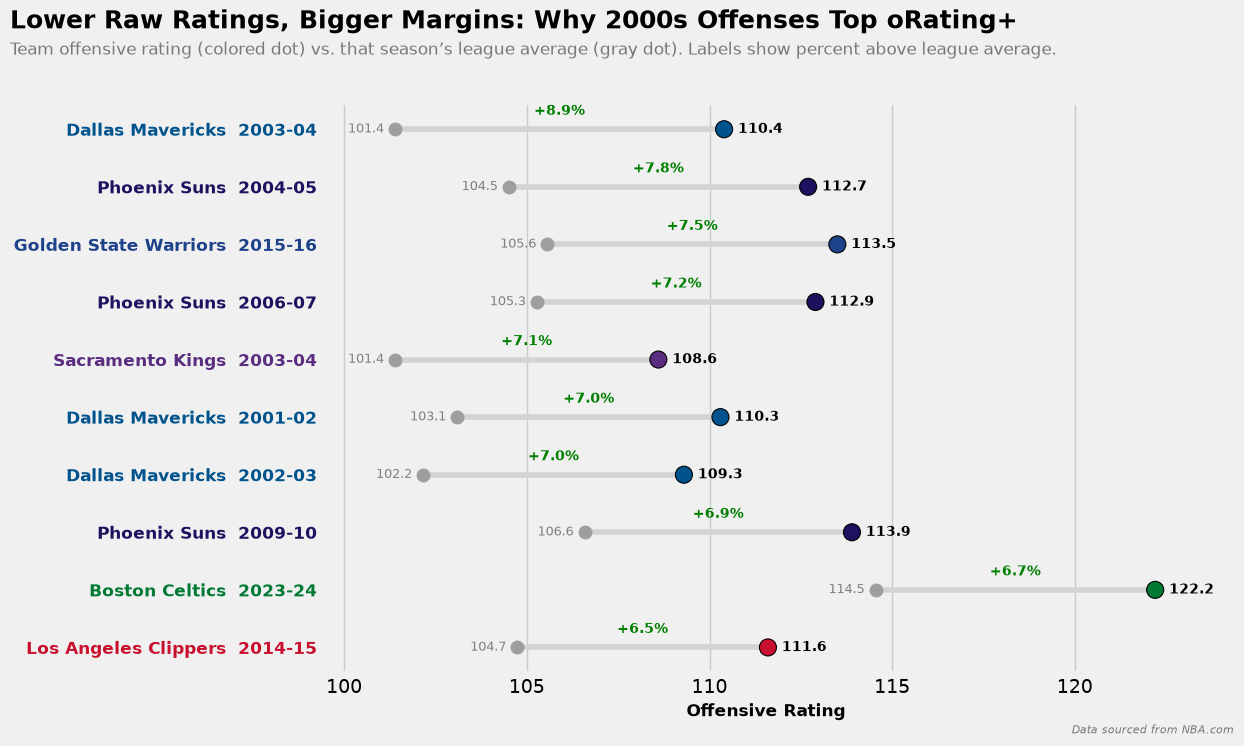

In [68]:
y = np.arange(len(top_10_orating_plus))
team_colors = [team_color_map.get(t, '#555555') for t in top_10_orating_plus['team_name']]
labels_plus = [f"{t}  {format_season(s)}"
          for t, s in zip(top_10_orating_plus['team_name'], top_10_orating_plus['season_end_year'])]
LEAGUE_COLOR = '#9E9E9E'

fig, ax = plt.subplots(figsize=(12, 7.5))

# Dumbbell: league average -> team ORtg
ax.hlines(y, top_10_orating_plus['league_off_rating'], top_10_orating_plus['off_rating'],
          color='lightgray', lw=4, zorder=1)
ax.scatter(top_10_orating_plus['league_off_rating'], y, color=LEAGUE_COLOR, s=90, zorder=2)
ax.scatter(top_10_orating_plus['off_rating'], y, color=team_colors, s=150,
           edgecolor='black', linewidth=0.8, zorder=3)

for yi, (team_v, lg_v) in enumerate(zip(top_10_orating_plus['off_rating'],
                                        top_10_orating_plus['league_off_rating'])):
    ax.annotate(f'{team_v:.1f}', xy=(team_v, yi), xytext=(10, 0),
                textcoords='offset points', va='center', fontsize=10, fontweight='bold')
    ax.annotate(f'{lg_v:.1f}', xy=(lg_v, yi), xytext=(-8, 0),
                textcoords='offset points', va='center', ha='right', fontsize=9, color='gray')
    # Percent change from league average, centered over the connecting line
    pct = (team_v - lg_v) / lg_v * 100
    mid_x = (team_v + lg_v) / 2
    ax.annotate(f'+{pct:.1f}%', xy=(mid_x, yi), xytext=(0, 8),
                textcoords='offset points', ha='center', va='bottom',
                fontsize=10, fontweight='bold', color='green')

ax.set_yticks(y)
ax.set_yticklabels(labels_plus, fontsize=12, fontweight='bold')
for tick_label, color in zip(ax.get_yticklabels(), team_colors):
    tick_label.set_color(color)

ax.invert_yaxis()   # best team at the top
ax.set_xlim(top_10_orating_plus['league_off_rating'].min() - 2,
            top_10_orating_plus['off_rating'].max() + 1.5)
ax.set_xlabel('Offensive Rating', fontsize=12, fontweight='bold')
ax.grid(axis='y', visible=False)

# Header and footer
fig.text(-0.04, 0.96, 'Lower Raw Ratings, Bigger Margins: Why 2000s Offenses Top oRating+', fontsize=18, fontweight='bold', ha='left')
fig.text(-0.04, 0.925,
         "Team offensive rating (colored dot) vs. that season’s league average (gray dot). Labels show percent above league average.",
         fontsize=12, alpha=0.5, ha='left')
fig.text(0.98, 0.02, 'Data sourced from NBA.com', fontsize=8, alpha=0.5,
         style='italic', ha='right')

fig.subplots_adjust(top=0.86, bottom=0.1, left=0.22, right=0.96)
plt.show()

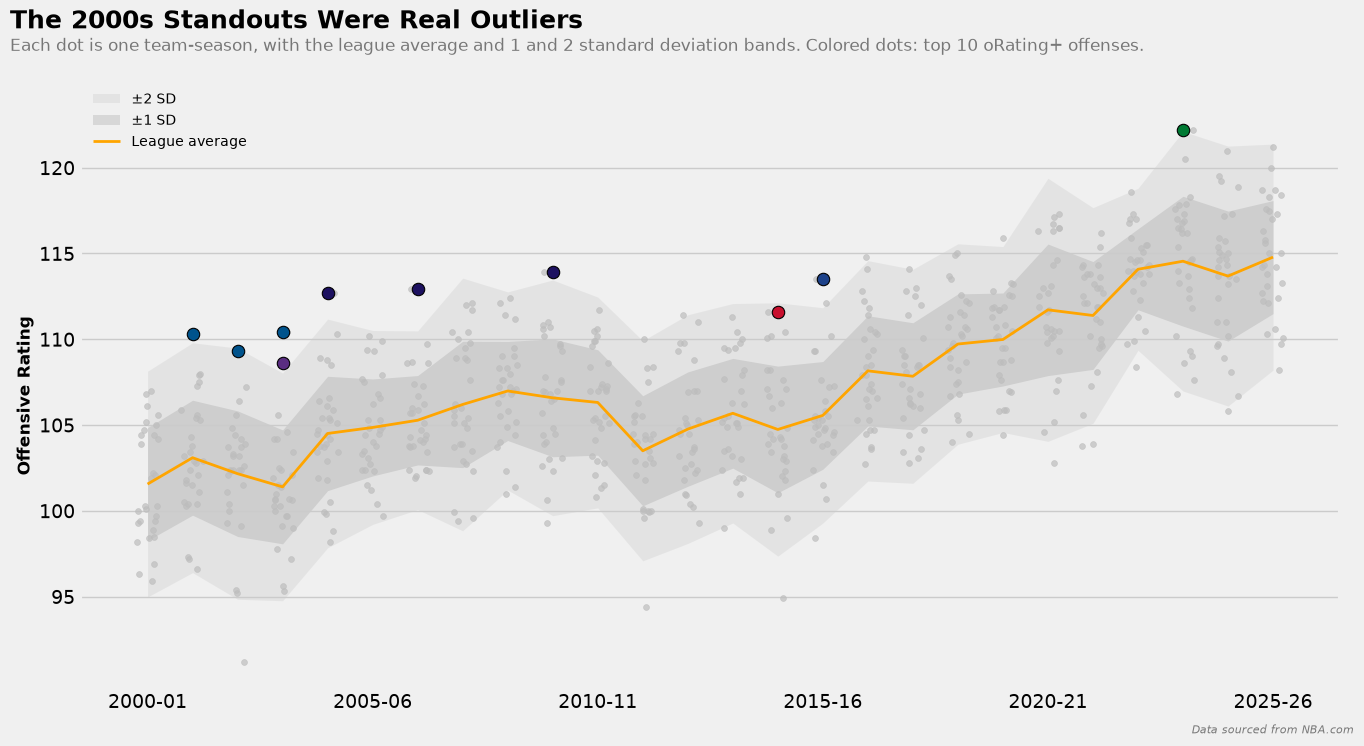

In [96]:
seasons = sorted(team_profile_df['season_end_year'].unique())
season_idx = {s: i for i, s in enumerate(seasons)}

# League average and standard deviation per season
lg = (team_profile_df.groupby('season_end_year', as_index=False)['league_off_rating']
      .first()
      .sort_values('season_end_year'))
sd = (team_profile_df.groupby('season_end_year')['off_rating']
      .std()
      .reindex(lg['season_end_year'])
      .values)
lg_x = lg['season_end_year'].map(season_idx).values
lg_y = lg['league_off_rating'].values

fig, ax = plt.subplots(figsize=(14, 7.5))

# ---- Team distribution with SD bands ----
rng = np.random.default_rng(42)
x = team_profile_df['season_end_year'].map(season_idx) + rng.uniform(-0.25, 0.25, len(team_profile_df))

ax.fill_between(lg_x, lg_y - 2 * sd, lg_y + 2 * sd, color='#9E9E9E', alpha=0.15,
                linewidth=0, zorder=0, label='±2 SD')
ax.fill_between(lg_x, lg_y - sd, lg_y + sd, color='#9E9E9E', alpha=0.3,
                linewidth=0, zorder=0, label='±1 SD')

ax.scatter(x, team_profile_df['off_rating'], color='#BDBDBD', s=18, alpha=0.7, zorder=1)
ax.plot(lg_x, lg_y, lw=2, zorder=2, color='orange', label='League average')

for _, row in top_10_orating_plus.iterrows():
    xi = season_idx[row['season_end_year']]
    ax.scatter(xi, row['off_rating'], color=team_color_map.get(row['team_name'], '#555555'),
               s=80, edgecolor='black', linewidth=0.8, zorder=3)

ax.set_ylabel('Offensive Rating', fontsize=12, fontweight='bold')
ax.set_yticks([95, 100, 105, 110, 115, 120])
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left', bbox_to_anchor=(0, 1.04), fontsize=10, frameon=False)

ax.set_xticks(range(0, len(seasons), 5))
ax.set_xticklabels([format_season(s) for s in seasons[::5]])

# ---- Header and footer ----
fig.text(0.02, 0.96, 'The 2000s Standouts Were Real Outliers', fontsize=18,
         fontweight='bold', ha='left')
fig.text(0.02, 0.93,
         'Each dot is one team-season, with the league average and 1 and 2 standard deviation bands. '
         'Colored dots: top 10 oRating+ offenses.',
         fontsize=12, alpha=0.5, ha='left')
fig.text(0.98, 0.02, 'Data sourced from NBA.com', fontsize=8, alpha=0.5,
         style='italic', ha='right')

fig.subplots_adjust(top=0.86, bottom=0.08, left=0.07, right=0.97)
plt.show()

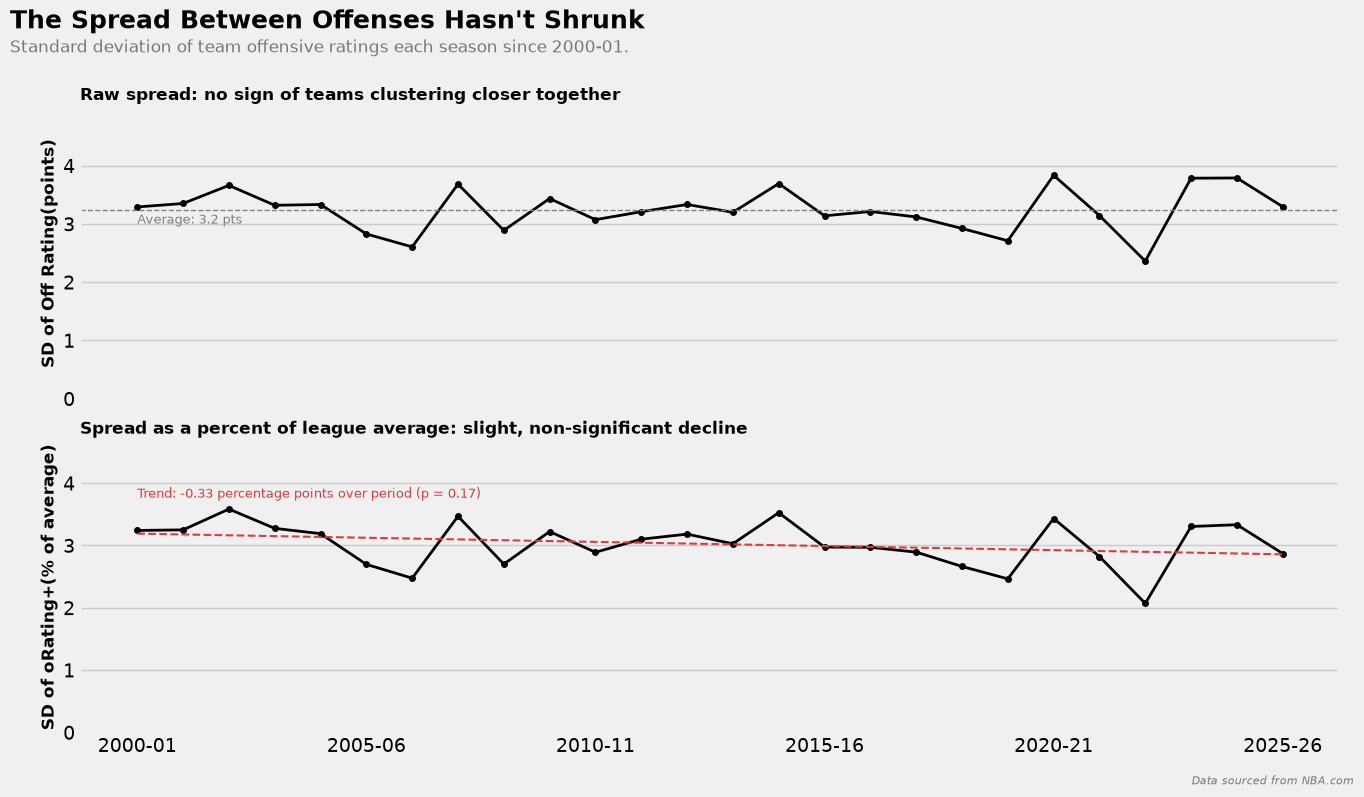

In [100]:
cv = sd / lg_y * 100
trend = linregress(lg_x, cv)

fig, (ax_raw, ax_pct) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                                     gridspec_kw={'hspace': 0.15})

# ---- Top: raw standard deviation (league compression test) ----
ax_raw.plot(lg_x, sd, color='black', lw=2, marker='o', markersize=4)
ax_raw.axhline(np.mean(sd), color='gray', lw=1, ls='--')
ax_raw.annotate(f'Average: {np.mean(sd):.1f} pts', xy=(lg_x[0], np.mean(sd)), xytext=(0, -3),
                textcoords='offset points', ha='left', va='top', fontsize=9, color='gray')
ax_raw.set_ylim(0, sd.max() * 1.3)
ax_raw.set_ylabel('SD of Off Rating(points)', fontsize=12, fontweight='bold')
ax_raw.set_title('Raw spread: no sign of teams clustering closer together',
                 loc='left', fontsize=12, fontweight='bold')
ax_raw.grid(axis='x', visible=False)

# ---- Bottom: SD as % of league average (ratio effect test) ----
ax_pct.plot(lg_x, cv, color='black', lw=2, marker='o', markersize=4)
ax_pct.plot(lg_x, trend.intercept + trend.slope * lg_x, color='#E03A3E', lw=1.5, ls='--')
ax_pct.annotate(f'Trend: {trend.slope * (len(lg_x) - 1):+.2f} percentage points over period (p = {trend.pvalue:.2f})',
                xy=(lg_x[0], cv.max() * 1.1), ha='left', va='top', fontsize=9, color='#E03A3E')
ax_pct.set_ylim(0, cv.max() * 1.3)
ax_pct.set_ylabel('SD of oRating+(% of average)', fontsize=12, fontweight='bold')
ax_pct.set_title('Spread as a percent of league average: slight, non-significant decline',
                 loc='left', fontsize=12, fontweight='bold')
ax_pct.grid(axis='x', visible=False)

ax_pct.set_xticks(range(0, len(seasons), 5))
ax_pct.set_xticklabels([format_season(s) for s in seasons[::5]])

# ---- Header and footer ----
fig.text(0.02, 0.96, "The Spread Between Offenses Hasn't Shrunk", fontsize=18,
         fontweight='bold', ha='left')
fig.text(0.02, 0.93, 'Standard deviation of team offensive ratings each season since 2000-01.',
         fontsize=12, alpha=0.5, ha='left')
fig.text(0.98, 0.015, 'Data sourced from NBA.com', fontsize=8, alpha=0.5,
         style='italic', ha='right')

fig.subplots_adjust(top=0.86, bottom=0.08, left=0.07, right=0.97)
plt.show()

In [98]:
res = linregress(lg_x, cv)
print(f'Slope per season: {res.slope:.3f} percentage points')
print(f'Change over full period: {res.slope * (len(lg_x) - 1):.2f} percentage points')
print(f'p-value: {res.pvalue:.3f}')

Slope per season: -0.013 percentage points
Change over full period: -0.33 percentage points
p-value: 0.169


In [73]:
sd_by_season = team_profile_df.groupby('season_end_year')['off_rating'].transform('std')
team_profile_df['off_rating_z'] = (
    (team_profile_df['off_rating'] - team_profile_df['league_off_rating']) / sd_by_season
)

top_10_z = team_profile_df.nlargest(10, 'off_rating_z')[
    ['team_name', 'season_end_year', 'off_rating', 'league_off_rating', 'off_rating_z']
]
top_10_z

,team_name,season_end_year,off_rating,league_off_rating,off_rating_z
198,Phoenix Suns,2007,112.9,105.276667,2.927175
91,Dallas Mavericks,2004,110.4,101.393103,2.713750
455,Golden State Warriors,2016,113.5,105.560000,2.530151
138,Phoenix Suns,2005,112.7,104.506667,2.458929
572,Dallas Mavericks,2020,115.9,109.983333,2.183873
110,Sacramento Kings,2004,108.6,101.393103,2.171415
34,Dallas Mavericks,2002,110.3,103.093103,2.151488
289,Phoenix Suns,2010,113.9,106.583333,2.130457
466,Oklahoma City Thunder,2016,112.1,105.560000,2.084029
485,Golden State Warriors,2017,114.8,108.156667,2.068485


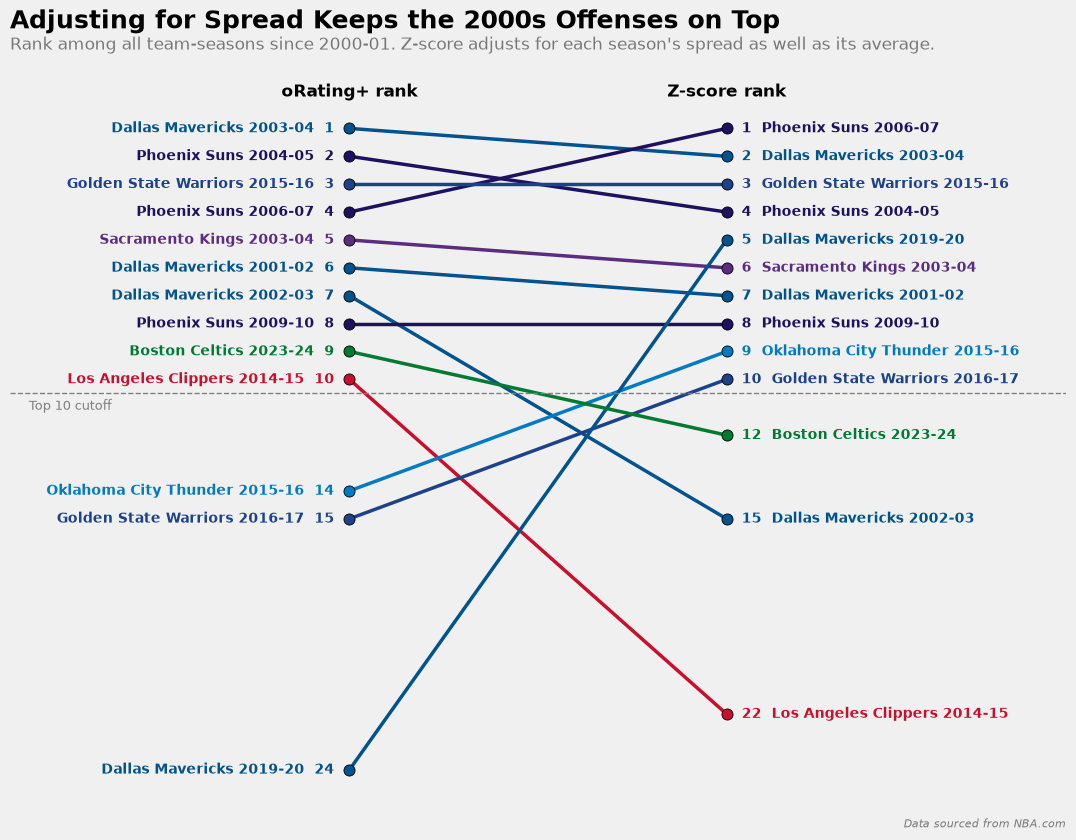

In [74]:
# Full rankings by each method
df = team_profile_df.copy()
df['rank_plus'] = df['team_orating_plus'].rank(ascending=False, method='first').astype(int)
df['rank_z'] = df['off_rating_z'].rank(ascending=False, method='first').astype(int)

# Every team that's top 10 in at least one method
union = df[(df['rank_plus'] <= 10) | (df['rank_z'] <= 10)]

fig, ax = plt.subplots(figsize=(11, 8.5))

for _, r in union.iterrows():
    color = team_color_map.get(r['team_name'], '#555555')
    label = f"{r['team_name']} {format_season(r['season_end_year'])}"

    ax.plot([0, 1], [r['rank_plus'], r['rank_z']], color=color, lw=2.5,
            marker='o', markersize=8, markeredgecolor='black', markeredgewidth=0.6)
    ax.text(-0.04, r['rank_plus'], f"{label}  {r['rank_plus']}", ha='right', va='center',
            fontsize=10, fontweight='bold', color=color)
    ax.text(1.04, r['rank_z'], f"{r['rank_z']}  {label}", ha='left', va='center',
            fontsize=10, fontweight='bold', color=color)

# Top 10 cutoff
ax.axhline(10.5, color='gray', lw=1, ls='--')
ax.text(-0.85, 11.2, 'Top 10 cutoff', ha='left', va='bottom', fontsize=9, color='gray')

# Column headers
ax.text(0, 0, 'oRating+ rank', ha='center', va='bottom', fontsize=12, fontweight='bold')
ax.text(1, 0, 'Z-score rank', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_xlim(-0.9, 1.9)
ax.invert_yaxis()
ax.axis('off')

fig.text(0.02, 0.96, 'Adjusting for Spread Keeps the 2000s Offenses on Top', fontsize=18, fontweight='bold', ha='left')
fig.text(0.02, 0.935,
         "Rank among all team-seasons since 2000-01. Z-score adjusts for each season's spread as well as its average.",
         fontsize=12, alpha=0.5, ha='left')
fig.text(0.98, 0.02, 'Data sourced from NBA.com', fontsize=8, alpha=0.5,
         style='italic', ha='right')

fig.subplots_adjust(top=0.88, bottom=0.05, left=0.02, right=0.98)
plt.show()

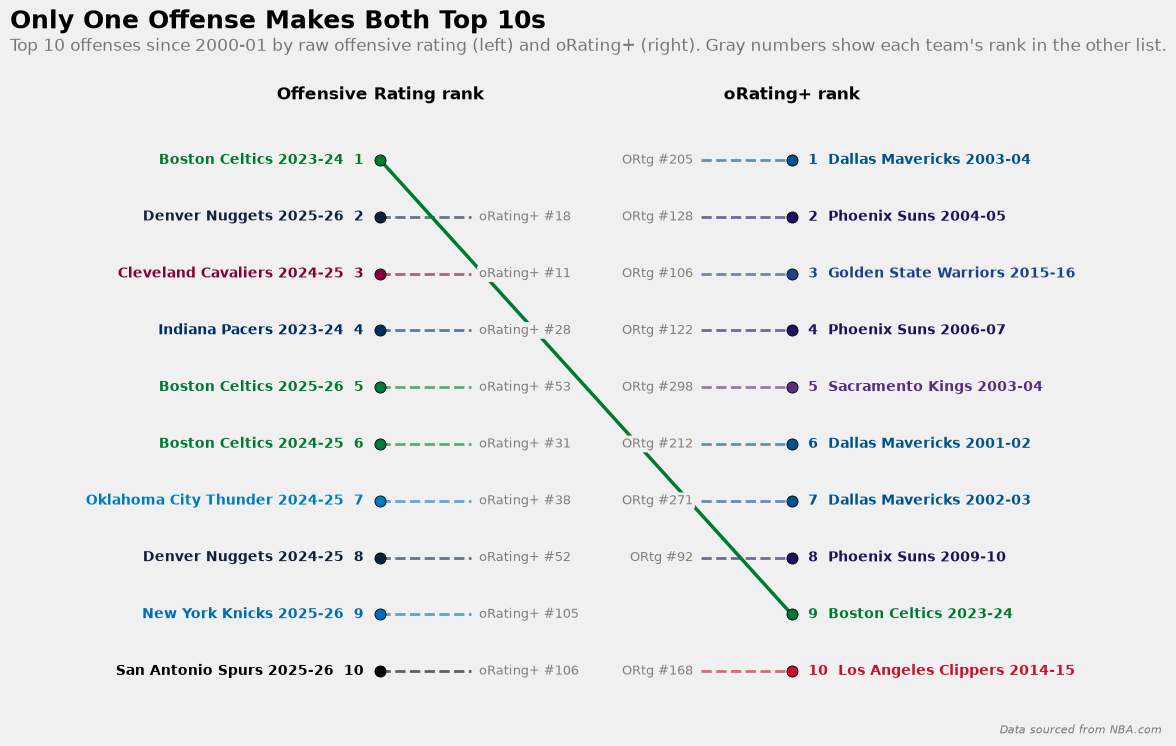

In [75]:
# Full rankings by each method, so we can show where each team lands in the other list
ranks = team_profile_df[['team_name', 'season_end_year', 'off_rating', 'team_orating_plus']].copy()
ranks['rank_ortg'] = ranks['off_rating'].rank(ascending=False, method='first').astype(int)
ranks['rank_plus'] = ranks['team_orating_plus'].rank(ascending=False, method='first').astype(int)

key = ['team_name', 'season_end_year']
union = (pd.concat([top_10_orating[key], top_10_orating_plus[key]])
         .drop_duplicates()
         .merge(ranks, on=key, how='left'))

fig, ax = plt.subplots(figsize=(12, 7.5))

# Background box so gray rank labels sit on top of any crossing lines
label_box = dict(boxstyle='round,pad=0.15', facecolor=ax.get_facecolor(), edgecolor='none')

for _, r in union.iterrows():
    color = team_color_map.get(r['team_name'], '#555555')
    label = f"{r['team_name']} {format_season(r['season_end_year'])}"
    rl, rr = r['rank_ortg'], r['rank_plus']
    in_left, in_right = rl <= 10, rr <= 10

    if in_left and in_right:
        # In both lists: full connecting line (drawn underneath the labels)
        ax.plot([0, 1], [rl, rr], color=color, lw=2.5, marker='o', markersize=8,
                markeredgecolor='black', markeredgewidth=0.6, zorder=2)
    elif in_left:
        # Only in raw ORtg top 10: short dashed stub + its oRating+ rank
        ax.plot([0, 0.22], [rl, rl], color=color, lw=2, ls='--', alpha=0.6, zorder=1)
        ax.scatter(0, rl, color=color, s=64, edgecolor='black', linewidth=0.6, zorder=3)
        ax.text(0.24, rl, f'oRating+ #{rr}', ha='left', va='center', fontsize=9,
                color='gray', bbox=label_box, zorder=4)
    else:
        # Only in oRating+ top 10: short dashed stub + its raw ORtg rank
        ax.plot([0.78, 1], [rr, rr], color=color, lw=2, ls='--', alpha=0.6, zorder=1)
        ax.scatter(1, rr, color=color, s=64, edgecolor='black', linewidth=0.6, zorder=3)
        ax.text(0.76, rr, f'ORtg #{rl}', ha='right', va='center', fontsize=9,
                color='gray', bbox=label_box, zorder=4)

    # Team labels on the outside edges
    if in_left:
        ax.text(-0.04, rl, f"{label}  {rl}", ha='right', va='center',
                fontsize=10, fontweight='bold', color=color)
    if in_right:
        ax.text(1.04, rr, f"{rr}  {label}", ha='left', va='center',
                fontsize=10, fontweight='bold', color=color)

# Column headers
ax.text(0, 0, 'Offensive Rating rank', ha='center', va='bottom', fontsize=12, fontweight='bold')
ax.text(1, 0, 'oRating+ rank', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_xlim(-0.9, 1.9)
ax.set_ylim(10.7, 0)   # rank 1 at the top
ax.axis('off')

fig.text(0.02, 0.96, "Only One Offense Makes Both Top 10s", fontsize=18, fontweight='bold', ha='left')
fig.text(0.02, 0.93,
         'Top 10 offenses since 2000-01 by raw offensive rating (left) and oRating+ (right). '
         'Gray numbers show each team\'s rank in the other list.',
         fontsize=12, alpha=0.5, ha='left')
fig.text(0.98, 0.02, 'Data sourced from NBA.com', fontsize=8, alpha=0.5,
         style='italic', ha='right')

fig.subplots_adjust(top=0.86, bottom=0.05, left=0.02, right=0.98)
plt.show()

In [101]:
import pandas as pd
from scipy.stats import spearmanr, kendalltau

N = 100
df = team_profile_df.copy()
df['rank_plus'] = df['team_orating_plus'].rank(ascending=False, method='first')
df['rank_z'] = df['off_rating_z'].rank(ascending=False, method='first')

top_plus = set(df.index[df['rank_plus'] <= N])
top_z = set(df.index[df['rank_z'] <= N])
both = top_plus & top_z
union = df.loc[sorted(top_plus | top_z)]

# 1. Overlap: how many teams appear in both top 100s
print(f'Overlap: {len(both)} of {N} teams appear in both lists')
print(f'Jaccard similarity: {len(both) / len(top_plus | top_z):.2f}')

# 2. Rank correlation: do the two methods order teams the same way?
rho, rho_p = spearmanr(union['rank_plus'], union['rank_z'])
tau, tau_p = kendalltau(union['rank_plus'], union['rank_z'])
print(f'Spearman rank correlation: {rho:.3f}')
print(f'Kendall tau: {tau:.3f}')

# 3. How far teams move between lists
shift = (union['rank_plus'] - union['rank_z']).abs()
print(f'Median rank change: {shift.median():.0f} spots')
print(f'Teams moving 10+ spots: {(shift >= 10).sum()} of {len(union)}')

# 4. Era composition: does either method favor a decade?
df['decade'] = ((df['season_end_year'] - 1) // 10 * 10).astype(str) + 's'
composition = pd.DataFrame({
    'oRating+ top 100': df.loc[df['rank_plus'] <= N, 'decade'].value_counts(),
    'Z-score top 100': df.loc[df['rank_z'] <= N, 'decade'].value_counts(),
}).fillna(0).astype(int).sort_index()
composition

Overlap: 92 of 100 teams appear in both lists
Jaccard similarity: 0.85
Spearman rank correlation: 0.855
Kendall tau: 0.664
Median rank change: 12 spots
Teams moving 10+ spots: 64 of 108


,oRating+ top 100,Z-score top 100
decade,,
2000s,42,39
2010s,40,40
2020s,18,21
